# كشكول التجارب: حساب جيب التمام والرسم البصري (المحاضرة 20)

أهلاً بيك! في الكشكول ده هنجرب نقيس الزاوية بين المتجهات باستخدام **Cosine Similarity**، ونشوف إزاي نرسم الكلمات بنقط على الشاشة!

القاعدة السحرية:
* لو المتجهين في نفس الاتجاه بالظبط (نفس المعنى) $\rightarrow$ التشابه بيكون **1.0**.
* لو المتجهين متعامدين (ملهمش علاقة ببعض) $\rightarrow$ التشابه بيكون **0.0**.
* لو عكس بعض تماماً $\rightarrow$ التشابه بيكون **-1.0**.

تعال نحسبها يدوي الأول ونرسمها!


In [1]:
# 1. دالة حساب تشابه جيب التمام ببساطة
import numpy as np

def simple_cosine_similarity(vec_a, vec_b):
    # ضرب القياسي مقسوم على طول المتجهين
    dot = np.dot(vec_a, vec_b)
    norm = np.linalg.norm(vec_a) * np.linalg.norm(vec_b)
    return dot / norm

# نجرب على متجهين صغيرين في بعدين (X, Y)
v_a = np.array([1, 2])
v_b = np.array([2, 4])  # نفس الاتجاه بالظبط (مضروب في 2)
v_c = np.array([-2, 1]) # متعامد مع v_a

print("تشابه المتجهين المتطابقين في الاتجاه:", round(simple_cosine_similarity(v_a, v_b), 3))
print("تشابه المتجهين المتعامدين:", round(simple_cosine_similarity(v_a, v_c), 3))


تشابه المتجهين المتطابقين في الاتجاه: 1.0
تشابه المتجهين المتعامدين: 0.0


### 2. تعال نحول جمل ونرسمها في بعدين (2D Plot)
هنكتب جمل من مجالات مختلفة (ذكاء اصطناعي، فلوس وبنوك، وطبخ)، ونضغط الـ 384 رقم في رقمين بس (X, Y) باستخدام أداة `PCA` عشان نقدر نشوفهم على الشاشة:


In [2]:
from sentence_transformers import SentenceTransformer
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

model = SentenceTransformer("all-MiniLM-L6-v2")

sentences = [
    "Machine learning neural network",
    "Deep learning AI algorithm",
    "Stock market interest rates",
    "Banking investment capital",
    "Delicious pasta with tomato sauce",
    "Grilled chicken and vegetables"
]

labels = ["AI", "AI", "Finance", "Finance", "Food", "Food"]

# نحسب المتجهات
vectors = model.encode(sentences)

# نضغط الأبعاد لبعدين بس (X, Y)
pca = PCA(n_components=2)
coords = pca.fit_transform(vectors)

print("تم ضغط الأبعاد بنجاح!")
for sent, (x, y) in zip(sentences, coords):
    print(f"  {sent[:30]:<30} -> X: {x:>6.2f}, Y: {y:>6.2f}")


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

تم ضغط الأبعاد بنجاح!
  Machine learning neural networ -> X:   0.51, Y:   0.38
  Deep learning AI algorithm     -> X:   0.59, Y:   0.39
  Stock market interest rates    -> X:  -0.59, Y:   0.33
  Banking investment capital     -> X:  -0.63, Y:   0.22
  Delicious pasta with tomato sa -> X:   0.03, Y:  -0.61
  Grilled chicken and vegetables -> X:   0.11, Y:  -0.71


### 3. رسم النقط وملاحظة التجمعات
بص على النقط في الرسمة دي: هتلاحظ إن جمل الـ AI قريبة من بعضها، وجمل الـ Finance متجمعة سوا، وجمل الـ Food في حتة تالتة خالص!


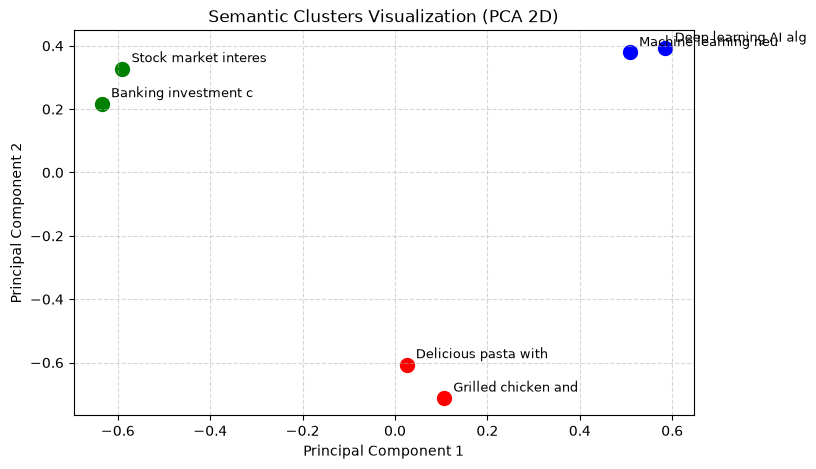

In [3]:
plt.figure(figsize=(8, 5))
colors = {"AI": "blue", "Finance": "green", "Food": "red"}

for idx, (x, y) in enumerate(coords):
    category = labels[idx]
    plt.scatter(x, y, color=colors[category], s=100)
    plt.text(x + 0.02, y + 0.02, sentences[idx][:20], fontsize=9)

plt.title("Semantic Clusters Visualization (PCA 2D)")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()


---
### مساحتك للتجربة الحرة
جرب تضيف جملة جديدة (مثلاً جملة عن الفضاء أو الرياضة) وشوف هتنزل فين على الرسمة بالنسبة للمجموعات التانية!


In [4]:
# جرب هنا:
# new_sentence = "Astronauts landed on the moon"
# احسب المتجه وشوف مكانه
